In [1]:
from typing import Annotated
from langchain_tavily import TavilySearch
from langchain_core.tools import tool
from langchain_experimental.utilities import PythonREPL
from langchain_core.messages import BaseMessage, HumanMessage
from langgraph.graph import StateGraph, START, END
from langchain.chat_models import init_chat_model

from dotenv import load_dotenv

load_dotenv()

llm = init_chat_model("openai:gpt-4.1")

# 1) 검색 도구 (Tavily API 필요)
tavily_tool = TavilySearch(max_results=5)

# 2) 로컬 파이썬 실행 도구 (차트 생성 전용)
repl = PythonREPL()

@tool
def python_repl_tool(
    code:Annotated[str, "차트를 생성하기 위한 파이썬 코드"]
):
    """파이썬 코드를 실행합니다. 출력은 print(...)로 표시해야 합니다."""
    try:
        result = repl.run(code)
    except BaseException as e:
        return f"실행 실패: {repr(e)}"
    return f"성공적으로 실행했습니다:\n'''python\n{code}\n'''Stdout:{result}\n\nFINAL ANSWER"

C:\Users\HKIT\AppData\Local\Temp\ipykernel_8820\1753464515.py:4: DeprecationWarning: `langchain-experimental` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-experimental/issues/87 for details.
  from langchain_experimental.utilities import PythonREPL


In [2]:
# 3) 시스템 프롬프트 템플릿
def make_system_prompt(suffix: str):
    return (
        "당신은 다른 어시스턴트와 협업하는 유능한 AI 입니다."
        "주어진 도구만 사용해 작업을 완수하세요."
        "최종 답변을 얻으면 반드시 'FINAL ANSWER'를 붙여 종료하세요."
        f"\n{suffix}"
    )

def get_next_node(last_message: BaseMessage, goto: str):
    if "FINAL ANSWER" in last_message.content:
        return END
    return goto

In [3]:
from typing import Literal
from langchain.agents import create_agent
from langgraph.graph import MessagesState
from langgraph.types import Command

# 4) 리서처 노드 (검색 전용)
research_agent = create_agent(
    model=llm,
    tools=[tavily_tool],
    system_prompt=make_system_prompt("당신은 리서치만 할 수 있습니다. 동료 차트 생성자와 협업하세요.")
)

def research_node(state:MessagesState) -> Command[Literal["chart_generator", END]]:
    result = research_agent.invoke(state)
    goto = get_next_node(result["messages"][-1], "chart_generator")
    # 일부 모델/프로바이더 제약 회피: 마지막 메시지를 Human 역할로 래핑
    result["messages"][-1] = HumanMessage(content=result["messages"][-1].content, name="researcher")
    return Command(update={"messages":result["messages"]}, goto=goto)

In [4]:
# 5) 차트 생성 노드 (파이썬 실행 전용)

chart_agent = create_agent(
    model=llm,
    tools=[python_repl_tool],
    system_prompt=make_system_prompt("당신은 차트 생성만 할 수 있습니다. 동료 리서처와 협업하세요.")
)

def chart_node(state: MessagesState) -> Command[Literal["researcher", END]]:
    result = chart_agent.invoke(state)
    goto = get_next_node(result["messages"][-1], "researcher")
    return Command(update={"messages":result["messages"]}, goto=goto)

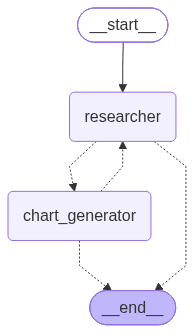

In [5]:
# 4 워크플로우 구성

from IPython.display import Image, display

# 6) 그래프 구성
workflow = StateGraph(MessagesState)
workflow.add_node("researcher", research_node)
workflow.add_node("chart_generator", chart_node)
workflow.add_edge(START,"researcher") # 리서처 부터 시작
graph = workflow.compile()

# 다이어그램 표시
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

{'researcher': {'messages': [HumanMessage(content='지난 1년간 달러 환율 데이터를 조사하고, 그 데이터를 기반으로 라인 차트를 만드세요.오늘은 2026-10-27입니다. 2026-10-27로부터 거슬러 지난 12개월 간의 USD/KRW 월별 환율을 조사하고 그 데이터를 기반으로 라인 차트를 만드세요.차트를 생성했으면 작업을 종료하세요.', additional_kwargs={}, response_metadata={}, id='44d33185-a0ca-4b6d-a196-0ab9142ab976'), AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 39, 'prompt_tokens': 1346, 'total_tokens': 1385, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4.1-2025-04-14', 'system_fingerprint': 'fp_2f4f94717c', 'id': 'chatcmpl-EdYgL32ma86Qyu70XGsS6lkP2NZTs', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_r

Python REPL can execute arbitrary code. Use with caution.
<string>:16: UserWarning: Glyph 50900 (\N{HANGUL SYLLABLE WEOL}) missing from font(s) DejaVu Sans.
<string>:16: UserWarning: Glyph 54872 (\N{HANGUL SYLLABLE HWAN}) missing from font(s) DejaVu Sans.
<string>:16: UserWarning: Glyph 50984 (\N{HANGUL SYLLABLE YUL}) missing from font(s) DejaVu Sans.
<string>:16: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from font(s) DejaVu Sans.
<string>:16: UserWarning: Glyph 52628 (\N{HANGUL SYLLABLE CU}) missing from font(s) DejaVu Sans.
<string>:16: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
c:\agent-prg\ch04\ch04_env\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 54872 (\N{HANGUL SYLLABLE HWAN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\agent-prg\ch04\ch04_env\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 50984 (\N{HANGUL SYLLABLE YUL}) missing from font(s)

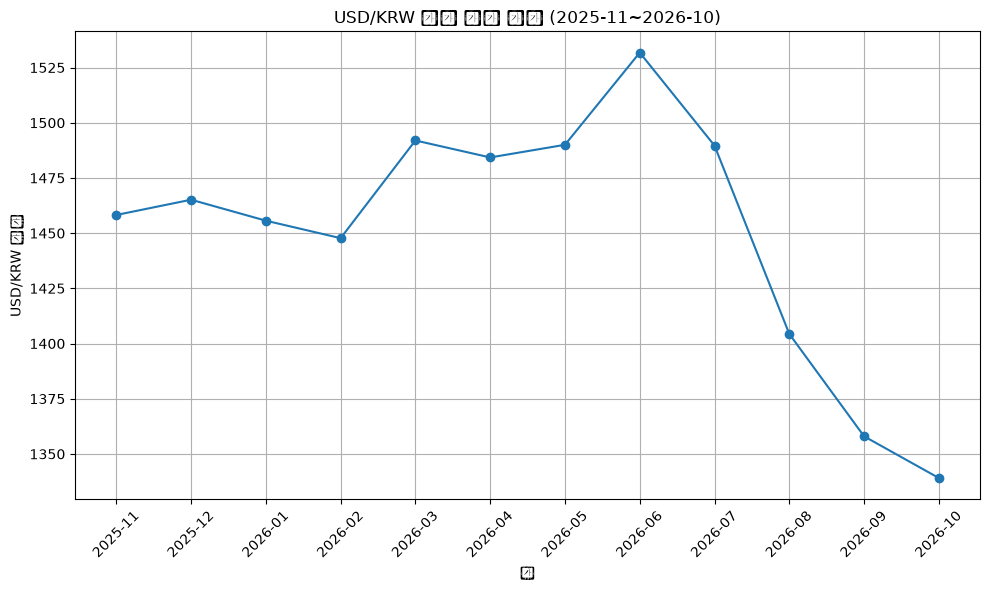

{'chart_generator': {'messages': [HumanMessage(content='지난 1년간 달러 환율 데이터를 조사하고, 그 데이터를 기반으로 라인 차트를 만드세요.오늘은 2026-10-27입니다. 2026-10-27로부터 거슬러 지난 12개월 간의 USD/KRW 월별 환율을 조사하고 그 데이터를 기반으로 라인 차트를 만드세요.차트를 생성했으면 작업을 종료하세요.', additional_kwargs={}, response_metadata={}, id='44d33185-a0ca-4b6d-a196-0ab9142ab976'), AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 39, 'prompt_tokens': 1346, 'total_tokens': 1385, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4.1-2025-04-14', 'system_fingerprint': 'fp_2f4f94717c', 'id': 'chatcmpl-EdYgL32ma86Qyu70XGsS6lkP2NZTs', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id=

In [6]:
# 멀티 에이전트 실행 : graph.stream()

from datetime import date

today = date.today()

events = graph.stream(
    {
        "messages":[(
            "user",
            "지난 1년간 달러 환율 데이터를 조사하고, 그 데이터를 기반으로 라인 차트를 만드세요."
            f"오늘은 {today}입니다. {today}로부터 거슬러 지난 12개월 간의 USD/KRW 월별 환율을 조사하고 그 데이터를 기반으로 라인 차트를 만드세요."
            "차트를 생성했으면 작업을 종료하세요."
        )]
    },
    {"recursion_limit":150} # 안전장치 최대 스텝 제한
)

for step in events:
    print(step) # 각 단계의 중간 결과/ 메시지 스트림 확인
    print("----")